# 01 · Datasets and audits

This notebook covers the three datasets of the combined track. MMFakeBench is a four-class benchmark with original, textual veracity distortion, visual veracity distortion and mismatch rows. VERITE labels image-caption pairs as true, miscaptioned or out-of-context. NewsCLIPpings labels image-caption pairs as pristine or falsified and is balanced by construction. This notebook only counts labels from the annotation files: no images are opened and no model is run.

In [1]:
import json
import csv
import collections
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parents[1]
FIG = ROOT / "MIDTERM_PRETRAINED_BASELINE" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
assert (ROOT / "data" / "raw").is_dir(), "repository root not found from notebook folder"

In [2]:
MMF_DIR = ROOT / "data" / "raw" / "MMFakeBench"
MMF_CLASSES = ["original", "textual_veracity_distortion", "visual_veracity_distortion", "mismatch"]

mmf = {
    split: json.loads((MMF_DIR / f"MMFakeBench_{split}.json").read_text(encoding="utf-8"))
    for split in ["val", "test"]
}
mmf_counts = pd.DataFrame(
    {split: collections.Counter(x["fake_cls"] for x in items) for split, items in mmf.items()}
).T.reindex(columns=MMF_CLASSES).fillna(0).astype(int)
mmf_counts["total"] = mmf_counts.sum(axis=1)
mmf_counts.index.name = "split"
display(mmf_counts)

,original,textual_veracity_distortion,visual_veracity_distortion,mismatch,total
split,,,,,
val,300,300,100,300,1000
test,3000,3000,1000,3000,10000


In [3]:
VERITE_CLASSES = ["true", "miscaptioned", "out-of-context"]

with open(ROOT / "data" / "raw" / "VERITE" / "VERITE.csv", newline="", encoding="utf-8") as f:
    verite_rows = list(csv.DictReader(f))

verite_counts = pd.Series(
    collections.Counter(r["label"] for r in verite_rows)
).reindex(VERITE_CLASSES).astype(int)
verite_df = pd.DataFrame({"n": verite_counts, "share": (verite_counts / len(verite_rows)).round(3)})
verite_df.index.name = "label"
display(verite_df)
print("total rows:", len(verite_rows))

,n,share
label,,
true,338,0.338
miscaptioned,338,0.338
out-of-context,325,0.325


total rows: 1001


In [4]:
NCP_DIR = ROOT / "data" / "raw" / "NewsCLIPpings" / "data" / "merged_balanced"

ncp = {
    split: json.loads((NCP_DIR / f"{split}.json").read_text(encoding="utf-8"))
    for split in ["train", "val", "test"]
}

ncp_label = pd.DataFrame([
    {
        "split": split,
        "total": len(payload["annotations"]),
        "pristine": sum(1 for a in payload["annotations"] if a["falsified"] is False),
        "falsified": sum(1 for a in payload["annotations"] if a["falsified"] is True),
    }
    for split, payload in ncp.items()
]).set_index("split")
display(ncp_label)

src_names = ncp["train"]["source_datasets"]
src_keys = sorted(src_names, key=int)
ncp_src = pd.DataFrame(
    {split: collections.Counter(str(a["source_dataset"]) for a in payload["annotations"])
     for split, payload in ncp.items()}
).T.reindex(columns=src_keys).fillna(0).astype(int)
ncp_src.columns = [f"{k}: {src_names[k]}" for k in src_keys]
ncp_src.index.name = "split"
display(ncp_src)

,total,pristine,falsified
split,,,
train,71072,35536,35536
val,7024,3512,3512
test,7264,3632,3632


,0: semantics_clip_text_image,1: semantics_clip_text_text,2: scene_resnet_place,3: person_sbert_text_text
split,,,,
train,17768,17768,17768,17768
val,1756,1756,1756,1756
test,1816,1816,1816,1816


In [5]:
def check(name, actual, expected):
    assert int(actual) == expected, f"{name}: expected {expected:,}, found {int(actual):,}"

check("MMFakeBench test rows", len(mmf["test"]), 10000)
check("MMFakeBench test original", mmf_counts.loc["test", "original"], 3000)
check("MMFakeBench test textual_veracity_distortion", mmf_counts.loc["test", "textual_veracity_distortion"], 3000)
check("MMFakeBench test visual_veracity_distortion", mmf_counts.loc["test", "visual_veracity_distortion"], 1000)
check("MMFakeBench test mismatch", mmf_counts.loc["test", "mismatch"], 3000)
check("MMFakeBench val rows", len(mmf["val"]), 1000)
check("VERITE rows", len(verite_rows), 1001)
check("VERITE true", verite_counts["true"], 338)
check("VERITE miscaptioned", verite_counts["miscaptioned"], 338)
check("VERITE out-of-context", verite_counts["out-of-context"], 325)
check("NewsCLIPpings train rows", ncp_label.loc["train", "total"], 71072)
check("NewsCLIPpings val rows", ncp_label.loc["val", "total"], 7024)
check("NewsCLIPpings val pristine", ncp_label.loc["val", "pristine"], 3512)
check("NewsCLIPpings val falsified", ncp_label.loc["val", "falsified"], 3512)
check("NewsCLIPpings test rows", ncp_label.loc["test", "total"], 7264)
check("NewsCLIPpings test pristine", ncp_label.loc["test", "pristine"], 3632)
check("NewsCLIPpings test falsified", ncp_label.loc["test", "falsified"], 3632)

print("all dataset counts match")

all dataset counts match


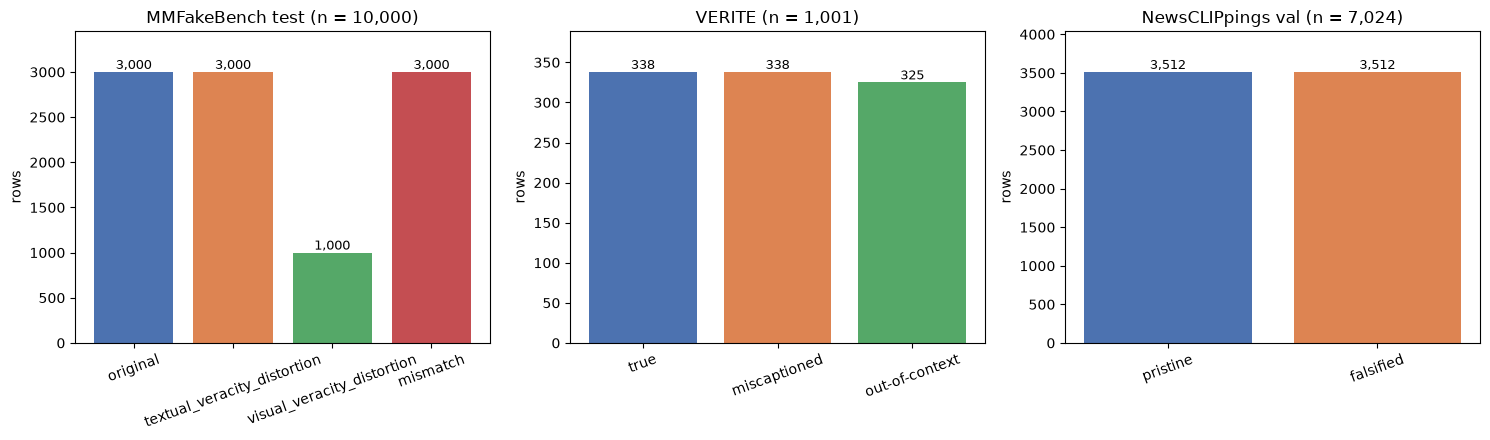

In [6]:
panels = [
    ("MMFakeBench test", mmf_counts.loc["test", MMF_CLASSES], len(mmf["test"])),
    ("VERITE", verite_counts, len(verite_rows)),
    ("NewsCLIPpings val", ncp_label.loc["val", ["pristine", "falsified"]], int(ncp_label.loc["val", "total"])),
]
colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (title, series, n) in zip(axes, panels):
    bars = ax.bar(series.index, series.values, color=colors[:len(series)])
    ax.set_title(f"{title} (n = {n:,})")
    ax.set_ylabel("rows")
    ax.tick_params(axis="x", rotation=20)
    ax.set_ylim(0, float(series.max()) * 1.15)
    for bar, value in zip(bars, series.values):
        ax.annotate(f"{int(value):,}", (bar.get_x() + bar.get_width() / 2, value),
                    ha="center", va="bottom", fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "01_class_balance.png", dpi=150)
plt.show()

## Integrity facts (static, from the Stage 00 audit; not recomputed here)

In [7]:
eda = json.loads((ROOT / "dashboard" / "eda.json").read_text(encoding="utf-8"))
mm = eda["datasets"]["MMFakeBench"]
vt = eda["datasets"]["VERITE"]
nc = eda["datasets"]["NewsCLIPpings"]

facts = pd.DataFrame([
    ("MMFakeBench", "referenced images present", mm["referenced_images_present"]),
    ("MMFakeBench", "test PNGs failing Pillow verify", f'{mm["test_png_failing_pillow_verify"]} ({mm["test_png_failure_reason"]})'),
    ("MMFakeBench", "duplicate normalized text groups", mm["duplicate_normalized_text_groups"]),
    ("MMFakeBench", "rows in duplicate normalized text groups", mm["duplicate_normalized_text_rows"]),
    ("MMFakeBench", "normalized text overlap with validation", mm["normalized_text_overlap_with_validation"]),
    ("MMFakeBench", "image-byte duplicate groups crossing val and test", mm["image_byte_duplicate_groups_crossing_val_test"]),
    ("MMFakeBench", "test rows with empty source metadata", f'{mm["test_rows_empty_source_metadata"]} ({mm["empty_source_metadata_label"]})'),
    ("MMFakeBench", "distinct source pairs", mm["distinct_source_pairs"]),
    ("MMFakeBench", "label-pure source pairs", mm["label_pure_source_pairs"]),
    ("VERITE", "rows in current CSV", vt["rows"]),
    ("VERITE", "documented rows", vt["documented_rows"]),
    ("VERITE", "documented class support", ", ".join(f"{k} {v}" for k, v in vt["documented_class_support"].items())),
    ("VERITE", "unique image basenames", vt["unique_image_basenames"]),
    ("VERITE", "archive files", vt["archive_files"]),
    ("NewsCLIPpings", "split recorded in audit", nc["split"]),
    ("NewsCLIPpings", "unique images streamed", nc["unique_images_streamed"]),
    ("NewsCLIPpings", "source-dataset strategies", nc["source_dataset_strategies"]),
    ("NewsCLIPpings", "rows per strategy", nc["rows_per_strategy"]),
], columns=["dataset", "fact", "value"])
display(facts.set_index(["dataset", "fact"]))

print("cross_cutting:")
for item in eda["cross_cutting"]:
    print("-", item)

value
dataset       fact                                                                                             
MMFakeBench   referenced images present                                                                   11000
              test PNGs failing Pillow verify                                                     1 (truncated)
              duplicate normalized text groups                                                               53
              rows in duplicate normalized text groups                                                      109
              normalized text overlap with validation                                                         3
              image-byte duplicate groups crossing val and test                                              28
              test rows with empty source metadata                           100 (all visual-distortion / Fake)
              distinct source pairs                                                                          14
              label-pure source pairs                                                                        13
VERITE        rows in current CSV                                                                          1001
              documented rows                                                                              1000
              documented class support                           true 338, miscaptioned 338, out-of-context 324
              unique image basenames                                                                        663
              archive files                                                                                 664
NewsCLIPpings split recorded in audit                                                                validation
              unique images streamed                                                                       5943
              source-dataset strategies                                                                       4
              rows per strategy                                                                            1756

cross_cutting:
- MMFakeBench test was inspected before evaluation.
- MMFakeBench source names encode the label (91.5% source-metadata rule).
- VERITE population mismatch (1,001 rows vs documented 1,000) is unresolved.
- NewsCLIPpings image-reuse terms are unresolved.


## Source pairs on MMFakeBench test (computed live)

Each MMFakeBench test row names a text source and an image source. If a pair always carries one label, the label can be guessed from the source names alone.

In [8]:
mmf_test = mmf["test"]
pair_labels = {}
for x in mmf_test:
    key = (x["text_source"] or "", x["image_source"] or "")
    pair_labels.setdefault(key, collections.Counter())[x["fake_cls"]] += 1

pair_rows = []
for (t_src, i_src), labels in pair_labels.items():
    n = sum(labels.values())
    row = {
        "text_source": t_src or "(empty)",
        "image_source": i_src or "(empty)",
        "n": n,
    }
    row.update({c: labels.get(c, 0) for c in MMF_CLASSES})
    row["pure"] = "yes" if len(labels) == 1 else "no"
    pair_rows.append(row)
pairs_df = pd.DataFrame(pair_rows).sort_values("n", ascending=False).reset_index(drop=True)
display(pairs_df)

distinct_pairs = len(pair_labels)
pure_pairs = sum(1 for labels in pair_labels.values() if len(labels) == 1)
assert distinct_pairs == 14, f"distinct pairs: {distinct_pairs}"
assert pure_pairs == 13, f"pure pairs: {pure_pairs}"

abl = json.loads((ROOT / "data" / "reports" / "baseline_study" / "mmfakebench_test_ablation_2026-10-25.json").read_text(encoding="utf-8"))
saved = abl["branches"]["paired"]["source_ceiling_in_sample"]
assert distinct_pairs == saved["distinct_pairs"], "distinct pairs differ from saved ablation"
assert pure_pairs == saved["pure_pairs"], "pure pairs differ from saved ablation"

rows_in_pure = int(pairs_df.loc[pairs_df["pure"] == "yes", "n"].sum())
ceiling = sum(max(labels.values()) for labels in pair_labels.values()) / len(mmf_test)
print(f"distinct pairs: {distinct_pairs}, label-pure pairs: {pure_pairs}")
print(f"rows in label-pure pairs: {rows_in_pure:,} of {len(mmf_test):,} ({rows_in_pure / len(mmf_test):.1%})")
print(f"source-name ceiling on all rows (majority label per pair): {ceiling:.1%}")
print(f"saved ablation ceiling: n = {saved['n']:,}, accuracy = {saved['accuracy']:.1%}")

,text_source,image_source,n,original,textual_veracity_distortion,visual_veracity_distortion,mismatch,pure
0,VisualNews,VisualNews,2000,2000,0,0,0,yes
1,Newsclipings,Newsclipings,1500,0,0,0,1500,yes
2,Fakeddit,Fakeddit,1000,500,0,500,0,no
3,Fever,AI-generated Image,1000,0,1000,0,0,yes
4,COCO-Counterfactuals,COCO-Counterfactuals,1000,0,0,0,1000,yes
5,Fakenewsnet,Repurposed Image,750,0,750,0,0,yes
6,MS-COCO,MS-COCO,500,500,0,0,0,yes
7,GPT-generated Rumor,Repurposed Image,500,0,500,0,0,yes
8,GPT-generated Rumor,AI-generated Image,500,0,500,0,0,yes
9,DGM4,DGM4,500,0,0,0,500,yes


distinct pairs: 14, label-pure pairs: 13
rows in label-pure pairs: 9,000 of 10,000 (90.0%)
source-name ceiling on all rows (majority label per pair): 95.0%
saved ablation ceiling: n = 9,999, accuracy = 95.0%


## How the dataset labels map onto one set of concepts

| Concept | MMFakeBench | VERITE | NewsCLIPpings |
|---|---|---|---|
| Textual distortion | textual veracity distortion | miscaptioned (interpretive bridge) | none |
| Visual distortion | visual veracity distortion | none | none |
| Cross-modal inconsistency | mismatch | out-of-context | falsified |
| Consistent pair | original | true | pristine |

MMFakeBench is the only dataset labelling all three concepts. Cross-modal inconsistency is the concept all three datasets share.

## Takeaways

- On MMFakeBench test, 13 of 14 source pairs carry one label, covering 9,000 of 10,000 rows. Assigning each pair its majority label reaches 95.0% on all rows, so source names alone predict most test labels.
- Constant guessing sets the floor for each dataset: 30.0% on MMFakeBench test (3,000 of 10,000), 33.8% on VERITE (338 of 1,001), and 50.0% on NewsCLIPpings test (3,632 of 7,264).
- Counts are reported per dataset and split, not pooled: MMFakeBench test has 10,000 rows, VERITE 1,001 and NewsCLIPpings validation 7,024, and VERITE's CSV holds one row more than its documented 1,000.